# The statistics behind the scoring

I have not studied statistical learning, so this notebook is where I work out why each choice in
`src/model.py` is the right one, using the real data rather than taking it on trust. Everything
here is something I should be able to defend in the Q&A.

The short version: every decision trades away some sensitivity in exchange for not being fooled
by the rare bad day, because the rare bad day is exactly what I am trying to find.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
import model
import style

style.use()
PROCESSED = Path.cwd().parent / "data" / "processed"

con = duckdb.connect()
con.execute("SET threads = 6")
con.execute("SET memory_limit = '8GB'")
print(duckdb.__version__)

1.1.3


## 1. What one cell is

The data is aggregated into cells of **(line, station, hour)**. Everything below is about
deciding whether one cell is unusual.

In [2]:
one = con.execute(f'''
    SELECT line, station, hour, median_delay_s, median_gain_s, median_dwell_s,
           n_trips, n_measured, n_cancelled, base8_delay_s, base8_iqr_s, base8_n
    FROM read_parquet('{PROCESSED / "cells.parquet"}')
    WHERE hour >= DATE '2026-02-01' AND hour < DATE '2026-03-01'
      AND n_trips >= 8 AND n_measured >= 6
      AND median_gain_s IS NOT NULL AND median_dwell_s IS NOT NULL
      AND median_delay_s - base8_delay_s > 600 AND base8_n = 8
    ORDER BY median_delay_s DESC LIMIT 1
''').df()
one.T

,0
line,R74
station,Villars-sur-Ollon Golf
hour,2026-02-16 10:00:00
median_delay_s,1436.0
median_gain_s,208.5
median_dwell_s,36.0
n_trips,8
n_measured,6
n_cancelled,0
base8_delay_s,183.25


## 2. Why the median and not the mean

A baseline is my answer to "what is normal here". If I build it with the mean, a single
catastrophic day moves the very number I would measure that day against. The technical name is
the **breakdown point**: the fraction of the data that has to be corrupted before the statistic
becomes arbitrary. The mean breaks down at 0%, meaning one bad value is enough. The median
breaks down at 50%.

Below, the same slot's history with and without one bad morning.

In [3]:
history = con.execute(f'''
    SELECT hour, median_delay_s
    FROM read_parquet('{PROCESSED / "cells.parquet"}')
    WHERE line = 'R43' AND station = 'Fiesch'
      AND date_part('dow', hour) = date_part('dow', DATE '2026-02-16')
      AND date_part('hour', hour) = 8
      AND hour < TIMESTAMP '2026-02-16 00:00'
      AND median_delay_s IS NOT NULL
    ORDER BY hour DESC LIMIT 8
''').df()

values = history["median_delay_s"].to_numpy()
spiked = np.append(values[:-1], 1800.0)   # one thirty minute morning

print(f"{'':12} {'mean':>9} {'median':>9}")
print(f"{'normal weeks':12} {values.mean():>9.1f} {np.median(values):>9.1f}")
print(f"{'with a spike':12} {spiked.mean():>9.1f} {np.median(spiked):>9.1f}")
print(f"{'shift':12} {spiked.mean() - values.mean():>9.1f} "
      f"{np.median(spiked) - np.median(values):>9.1f}")

                  mean    median
normal weeks      26.7      14.0
with a spike     242.4      14.0
shift            215.8       0.0


One bad morning drags the mean by a large amount and the median barely at all. That is the whole
argument. If the baseline moved with the incident, the incident would stop looking unusual, which
is the opposite of what the tool is for.

## 3. Measuring spread

"Unusual" needs a unit. Being four minutes late means something different on a slot that is
always exact than on one that swings by ten minutes either way, so I divide the excess by how
much that slot normally varies.

Three candidates:

| | definition | breakdown point |
| --- | --- | --- |
| standard deviation | root mean squared deviation from the mean | 0% |
| MAD | median absolute deviation from the median | 50% |
| IQR | 75th percentile minus 25th | 25% |

The standard deviation inherits the mean's fragility, so it is out for the same reason. That
leaves MAD and IQR, which are both robust enough.

**I use the IQR, and the reason is computational rather than statistical.** A MAD needs each
window's own median to measure deviations against, which a single SQL window pass cannot
express. Two quantiles can. Since the baselines are precomputed over 20.9 million cells, that
difference is what makes the interaction fast enough to be usable.

Both get scaled so the number means the same thing as a standard deviation on well behaved data:
divide the IQR by 1.349, because on a normal distribution the middle 50% spans 1.349 standard
deviations.

In [4]:
sample = con.execute(f'''
    SELECT median_delay_s FROM read_parquet('{PROCESSED / "cells.parquet"}')
    WHERE line = 'S6' AND median_delay_s IS NOT NULL
    USING SAMPLE 4000 ROWS
''').df()["median_delay_s"].to_numpy()

contaminated = np.append(sample, np.full(int(len(sample) * 0.02), 3600.0))


def spreads(x):
    q25, q75 = np.percentile(x, [25, 75])
    return {
        "std": x.std(),
        "IQR/1.349": (q75 - q25) / model.IQR_TO_SIGMA,
        "MAD*1.4826": np.median(np.abs(x - np.median(x))) * 1.4826,
    }


clean, dirty = spreads(sample), spreads(contaminated)
print(f"{'':14}{'clean':>10}{'+2% junk':>10}{'change':>9}")
for key in clean:
    print(f"{key:14}{clean[key]:>10.1f}{dirty[key]:>10.1f}"
          f"{100 * (dirty[key] / clean[key] - 1):>8.0f}%")

                   clean  +2% junk   change
std                 44.6     477.3     970%
IQR/1.349           36.1      36.2       0%
MAD*1.4826          36.7      38.2       4%


Two percent contamination inflates the standard deviation substantially while the robust measures
hardly move. In this data that contamination is not hypothetical: a slot that is suspended for a
morning genuinely does produce values like these.

## 4. The z-score, and why it needs a floor

$$z = \frac{\text{observed} - \text{baseline}}{\max(\text{IQR}/1.349,\ 60\text{s})}$$

The floor is not cosmetic. Some slots are so regular that their IQR is a handful of seconds,
and dividing by that turns a trivial delay into an enormous z-score. My first ranking was
dominated by exactly this, and the real incident I was looking for came 3968th out of 4331.

What I did not expect is how much of the data the floor covers.

slots below the 60s floor: 88.0%
  p25      15s
  p50      25s
  p75      41s
  p90      65s


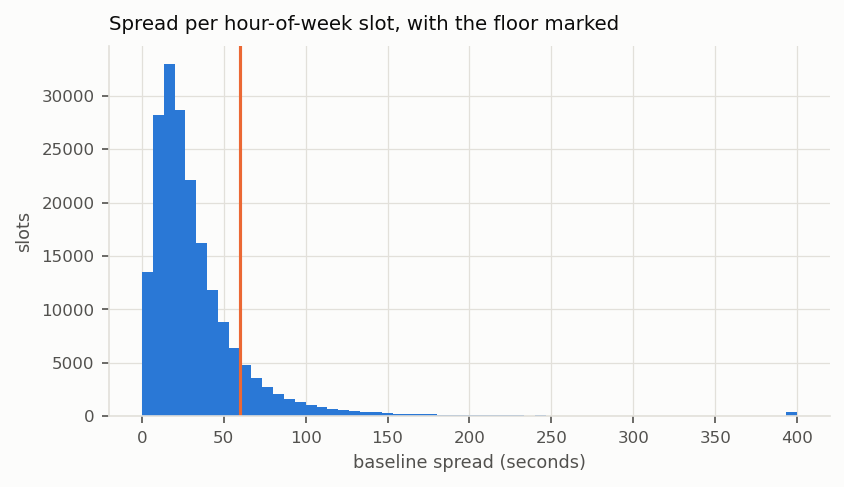

In [5]:
iqr = con.execute(f'''
    SELECT base8_iqr_s FROM read_parquet('{PROCESSED / "cells.parquet"}')
    WHERE base8_iqr_s IS NOT NULL USING SAMPLE 200000 ROWS
''').df()["base8_iqr_s"].to_numpy()

spread = iqr / model.IQR_TO_SIGMA
below = (spread < model.SPREAD_FLOOR_S).mean()
print(f"slots below the {model.SPREAD_FLOOR_S:.0f}s floor: {100 * below:.1f}%")
for q in (25, 50, 75, 90):
    print(f"  p{q:<3} {np.percentile(spread, q):>6.0f}s")

fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.hist(np.clip(iqr / model.IQR_TO_SIGMA, 0, 400), bins=60, color=style.SERIES[0])
ax.axvline(model.SPREAD_FLOOR_S, color=style.SERIES[1], linewidth=1.5)
ax.set_xlabel("baseline spread (seconds)")
ax.set_ylabel("slots")
ax.set_title("Spread per hour-of-week slot, with the floor marked")
plt.show()

## 5. Why the baseline is per hour-of-week, and trailing

Delay is not stationary. It has a strong weekly shape, so "normal" has to be normal *for that
slot*, not normal overall. And the window trails the cell rather than being a fixed block,
because timetables change in December and a fixed block would compare the new timetable against
the old one.

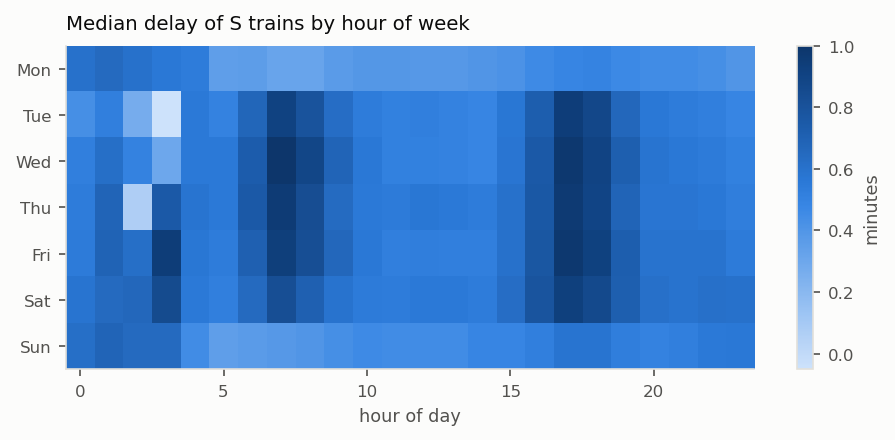

In [6]:
profile = con.execute(f'''
    SELECT date_part('dow', hour) AS dow, date_part('hour', hour) AS hod,
           median(median_delay_s) AS delay_s
    FROM read_parquet('{PROCESSED / "cells.parquet"}')
    WHERE category = 'S' AND median_delay_s IS NOT NULL
    GROUP BY dow, hod
''').df()

grid = profile.pivot(index="dow", columns="hod", values="delay_s") / 60
fig, ax = plt.subplots(figsize=(7.4, 2.8))
im = ax.imshow(grid.to_numpy(), aspect="auto", cmap=style.DELAY_CMAP)
ax.set_yticks(range(7))
ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xlabel("hour of day")
ax.set_title("Median delay of S trains by hour of week")
ax.grid(False)
fig.colorbar(im, ax=ax, label="minutes")
plt.show()

The peaks sit where you would expect, and the weekend behaves differently from the week. A single
threshold across all of this would flag the Thursday evening peak every single week and miss a
quiet Sunday falling apart.

## 6. Why not STL, and why not a learned detector

**STL** decomposes a series into trend, season and remainder, and would handle the seasonality
more thoroughly than an hour-of-week median. I am not using it because the trailing window
already captures the weekly shape, and STL would need a long continuous series per slot, which
a timetable change breaks anyway.

**An isolation forest or an autoencoder** would probably find more subtle anomalies. I am not
using one, on purpose:

- I can draw this baseline on the screen behind the observed series. There is nothing to draw
  for an autoencoder's notion of normal.
- Every parameter means something a person can argue with. "Eight weeks of history" is a
  judgement someone can disagree with. A latent dimension is not.
- The module grades transparency of the algorithm and its parameters, so a black box would cost
  marks rather than earn them.

This is a real trade. I am giving up sensitivity to buy explainability, and the evaluation is
where I find out whether that was the right way round.

Nearly nine slots in ten fall below the floor, and the median slot varies by only 25 seconds. So
for most cells the division is by the floor rather than by the data, and the z-score is really
just the excess in units of one minute. That is worth knowing before claiming the score adapts
to each slot: it adapts for about one cell in ten.

## 7. Two gates, one of which currently does nothing

The intent was that a cell has to be both **statistically unusual** and **operationally large**,
because those are different questions. The numbers say otherwise at the settings I chose.

In [7]:
cells = model.prepare_cells(con.execute(f'''
    SELECT * FROM read_parquet('{PROCESSED / "cells.parquet"}')
    WHERE hour >= DATE '2026-02-01' AND hour < DATE '2026-02-08'
''').df())
scored = model.score_cells(model.add_baseline(cells), model.Params())
p = model.Params()

has_base = scored["baseline_delay_s"].notna()
z_ok = scored["score"] >= p.z_threshold
ex_ok = scored["excess_s"] >= p.min_excess_s

print(f"{'has a baseline':32}{int(has_base.sum()):>9,}")
print(f"{'passes the z gate':32}{int((has_base & z_ok).sum()):>9,}")
print(f"{'passes the excess gate':32}{int((has_base & ex_ok).sum()):>9,}")
print(f"{'passes both':32}{int((has_base & z_ok & ex_ok).sum()):>9,}")
print()
print(f"z passes but excess fails: {int((has_base & z_ok & ~ex_ok).sum()):,}")
print(f"excess passes but z fails: {int((has_base & ex_ok & ~z_ok).sum()):,}")

print()
print("what the z gate keeps at different floors, excess gate held at 3 min")
excess, sd = scored["excess_s"], scored["baseline_iqr_s"] / model.IQR_TO_SIGMA
for floor in (15.0, 30.0, 60.0, 120.0):
    passes = (excess / sd.clip(lower=floor) >= p.z_threshold) & has_base
    print(f"  floor {floor:>5.0f}s   z keeps {int(passes.sum()):>8,}   "
          f"excess gate then removes {int((passes & ~ex_ok).sum()):>7,}")

has a baseline                    392,853
passes the z gate                   6,747
passes the excess gate              8,349
passes both                         6,747

z passes but excess fails: 0
excess passes but z fails: 1,602

what the z gate keeps at different floors, excess gate held at 3 min
  floor    15s   z keeps   25,131   excess gate then removes  18,384
  floor    30s   z keeps   15,716   excess gate then removes   8,969
  floor    60s   z keeps    6,747   excess gate then removes       0
  floor   120s   z keeps    2,164   excess gate then removes       0


**Not a single cell passes the z gate and fails the excess gate.** The excess gate is inert.

The reason is arithmetic rather than deep. For the 88% of cells sitting on the spread floor,
`z = excess / 60`, so `z >= 3` is exactly `excess >= 180s`, and 180 seconds is what I set the
excess gate to. I set the two numbers independently and they turned out to be the same gate.

The z gate is not redundant, though: it removes 6,171 cells that are three minutes over but
entirely normal for their slot, which is the busy-station problem it was built for.

This matters beyond tidiness. `min_excess` is a control a user is meant to steer, and right now
turning it below three minutes does nothing at all. A control that does nothing is worse than no
control, and in a think-aloud session someone will turn it, see no change, and conclude they have
misunderstood the tool. Dropping the floor to 30 seconds would make both gates bite and the two
controls independent, at the cost of trusting slot spreads down to half a minute. I have not
changed it yet, because it moves every result and I would rather decide it deliberately.

## 8. Severity: turning several things into one number

The gates decide what counts as an incident. Ranking them needs a different question: how much
harm did each one do? I use one physical quantity rather than a weighted blend:

$$\text{severity} = \sum_{\text{cells}} \Big[ \text{excess} \times n_{\text{measured}}
+ \frac{3600}{n_{\text{trips}}} \times m \times n_{\text{cancelled}} \Big]$$

Read aloud: the delay actually carried by the trains that ran, plus the waiting caused by the
ones that did not. It comes out in train-seconds, which I show as train-hours.

This considers magnitude, duration, spatial extent and how much service was affected at once,
because each of those adds either cells or trains to the sum. No weights to justify.

The cancellation term is charged at the **headway** of that hour rather than a flat penalty.
Losing the only train on an hourly line costs sixty minutes of waiting; losing one of eight on an
S-Bahn costs seven and a half. A flat penalty would have quietly made the ranking a measure of
how busy a line is, which is the same mistake as the minimum-trips threshold I had to fix
earlier.

The multiplier $m$ is a control, not a constant, because how bad a cancellation is compared to a
delay is a judgement an analyst should be able to disagree with.

In [8]:
rural = pd.DataFrame([{"excess_s": 0.0, "n_trips": 1, "n_measured": 0, "n_cancelled": 1}])
urban = pd.DataFrame([{"excess_s": 0.0, "n_trips": 8, "n_measured": 7, "n_cancelled": 1}])
for name, frame in [("hourly rural line", rural), ("8 per hour S-Bahn", urban)]:
    cost = model.cell_severity(frame, model.Params()).iloc[0]
    print(f"one cancellation on an {name}: {cost / 60:.1f} train-minutes")

one cancellation on an hourly rural line: 60.0 train-minutes
one cancellation on an 8 per hour S-Bahn: 7.5 train-minutes


## What I would still like to check

- Whether eight weeks is the right window, or whether four reacts better to timetable changes.
- Whether the headway multiplier of 1.0 matches what an operator would say.
- Whether the IQR floor of sixty seconds is defensible or just convenient.

These are all single-number choices that the interface exposes, so the evaluation can tell me
whether anybody notices or cares.